### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DOFM_Y = data.copy()
mask = (DOFM_Y['category']=='oil and fats') & (DOFM_Y['region']=='Yangon')
DOFM_Y = DOFM_Y[mask]
DOFM_Y.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
1100,1/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,3087.34,1.7345
1203,2/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2973.68,1.6706
1314,3/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2910.92,1.6353
1420,4/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2858.37,1.6058
1530,5/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2912.63,1.6363


In [13]:
DOFM_Y = DOFM_Y[['date', 'price']]
DOFM_Y['date'] = pd.to_datetime(DOFM_Y['date'])
mask = (DOFM_Y['date']>=obv_st_date) & (DOFM_Y['date']<=obv_end_date)
DOFM_Y = DOFM_Y.loc[mask]
DOFM_Y = DOFM_Y.set_index('date')
DOFM_Y.head()

,price
date,
2009-01-15,3087.34
2009-02-15,2973.68
2009-03-15,2910.92
2009-04-15,2858.37
2009-05-15,2912.63


In [14]:
DOFM_Y = DOFM_Y.resample('MS').mean()
DOFM_Y.head()

,price
date,
2009-01-01,3087.34
2009-02-01,2973.68
2009-03-01,2910.92
2009-04-01,2858.37
2009-05-01,2912.63


In [15]:
price = DOFM_Y['price']
date = DOFM_Y.index

##### Normalization data

In [16]:
scaler = MinMaxScaler()

In [17]:
DOFM_Y = scaler.fit_transform(DOFM_Y)
DOFM_Y = pd.DataFrame(DOFM_Y)
DOFM_Y.head()

,0
0,0.235625
1,0.197710
2,0.176774
3,0.159244
4,0.177344


In [18]:
DOFM_Y['date']=date
DOFM_Y = DOFM_Y.set_index('date')
DOFM_Y.columns=['price']
DOFM_Y.head()

,price
date,
2009-01-01,0.235625
2009-02-01,0.197710
2009-03-01,0.176774
2009-04-01,0.159244
2009-05-01,0.177344


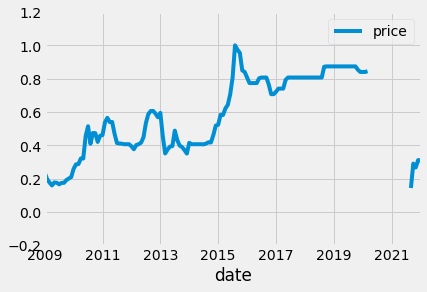

In [19]:
DOFM_Y.plot(grid=True)
plt.show()

In [20]:
DOFM_Y = DOFM_Y.interpolate(method="linear")
DOFM_Y.shape

(157, 1)

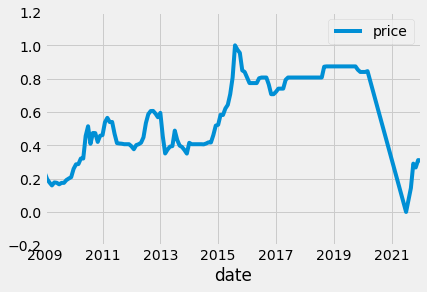

In [21]:
DOFM_Y.plot(grid=True)
plt.show()

It has positive trend.

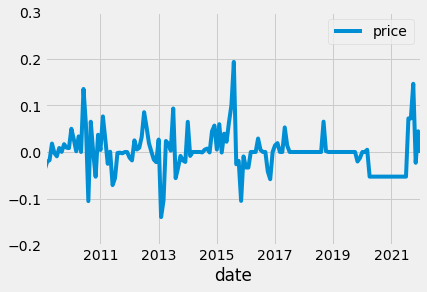

In [22]:
DOFM_Y_diff1 = DOFM_Y.diff(1).dropna()
DOFM_Y_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [23]:
RW_DOFM_Y= adfuller(DOFM_Y_diff1)
RW_DOFM_Y[1] # print P-value. If p-value<5%, reject null hypothesis

2.228652455198949e-14

##### Plotting ACF and PACF

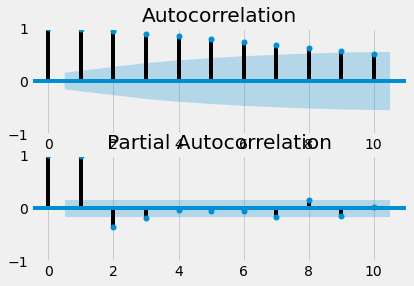

In [24]:
fig, axes=plt.subplots(2,1)
plot_acf(DOFM_Y, lags=10, ax=axes[0])
plot_pacf(DOFM_Y, lags=10, ax=axes[1])
plt.show()

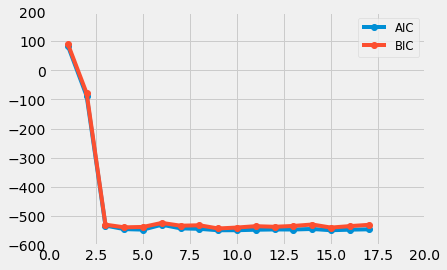

In [25]:
AIC, BIC = AIC_BIC_withOrderRange(DOFM_Y, p=3, d=2, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 
# 6:(1,0,0), 7:(1,0,1), 8:(1,0,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 
# 12:(2,0,0), 13:(2,0,1), 14:(2,0,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [26]:
AIC, BIC

(array([ 289.41780914,   84.37389262,  -87.97967692, -532.28083134,
        -544.465126  , -546.21827123, -529.32285205, -541.9605964 ,
        -543.50099827, -548.40045944, -548.22320765, -546.61232402,
        -545.6570795 , -545.84549218, -543.95155218, -548.35947093,
        -546.41192947, -545.13621613]),
 array([ 292.47405494,   90.48638423,  -78.81093951, -529.23097533,
        -538.36541399, -537.06870321, -523.21036044, -532.79185898,
        -531.27601504, -542.30074743, -539.07363963, -534.4129    ,
        -536.48834208, -533.62050896, -528.67032315, -539.20990291,
        -534.21250544, -529.88693609]))

We will run again 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [28]:
mod_orders = [
    (0,1,0), 
    (0,1,1), 
    (0,1,2), 
    (1,1,0), 
    (1,1,1), 
    (1,1,2), 
    (2,1,0), 
    (2,1,1), 
    (2,1,2)
]

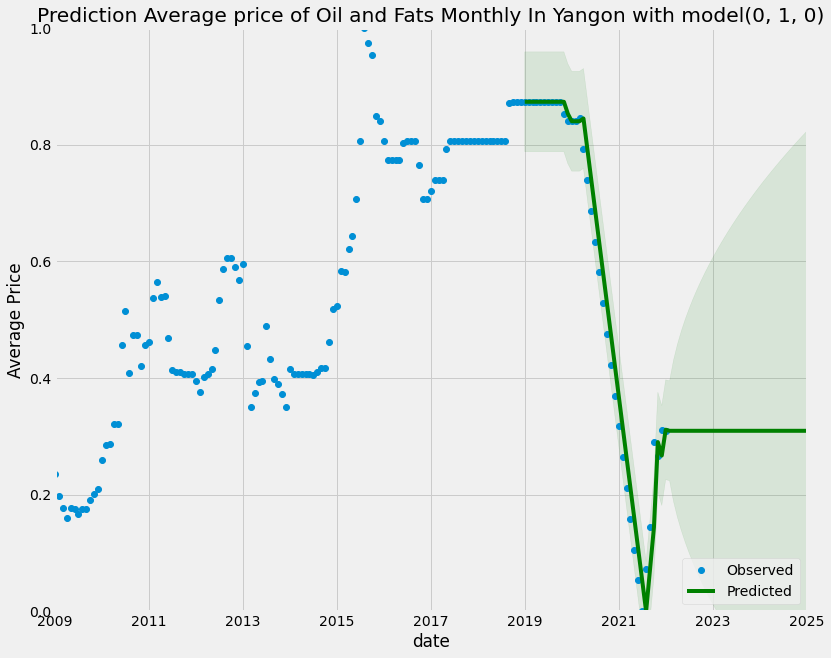

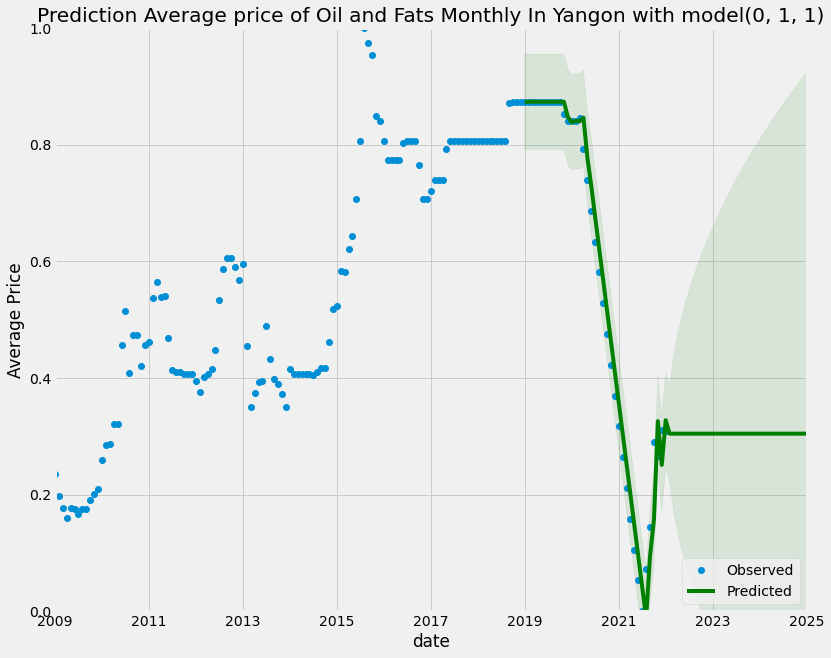

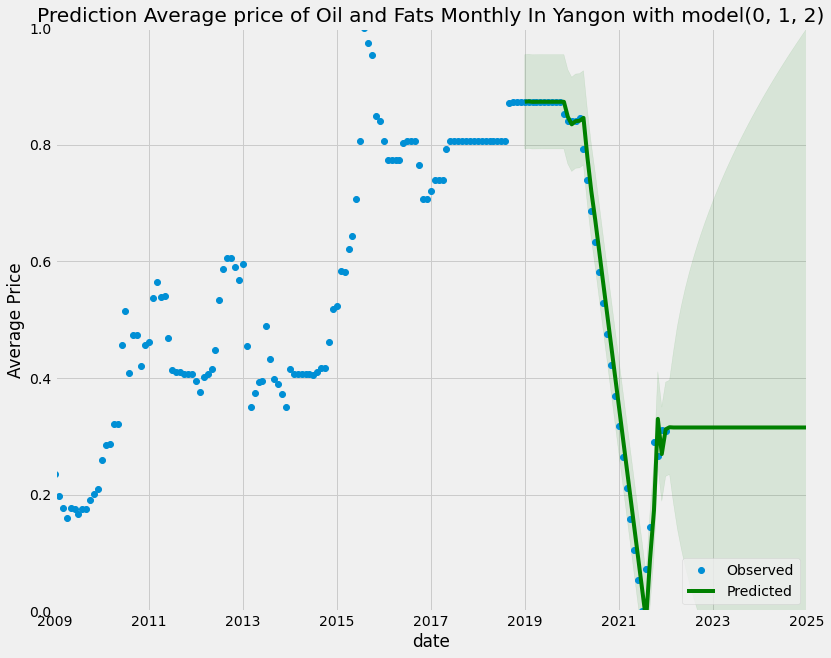

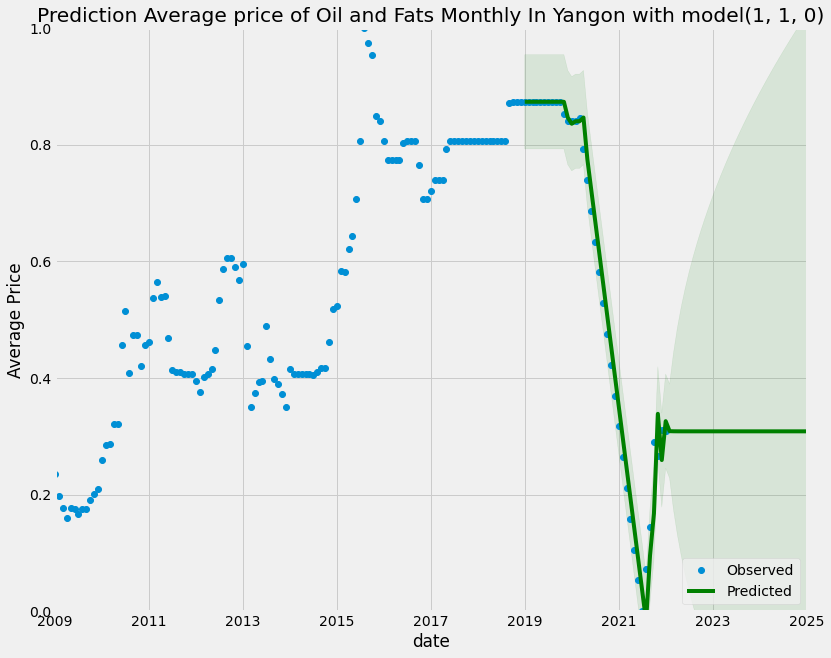

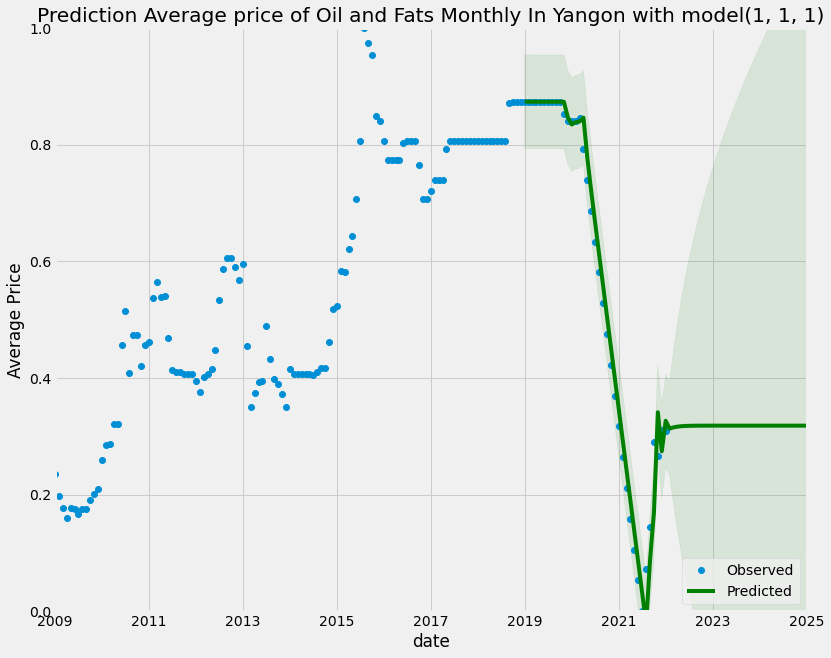

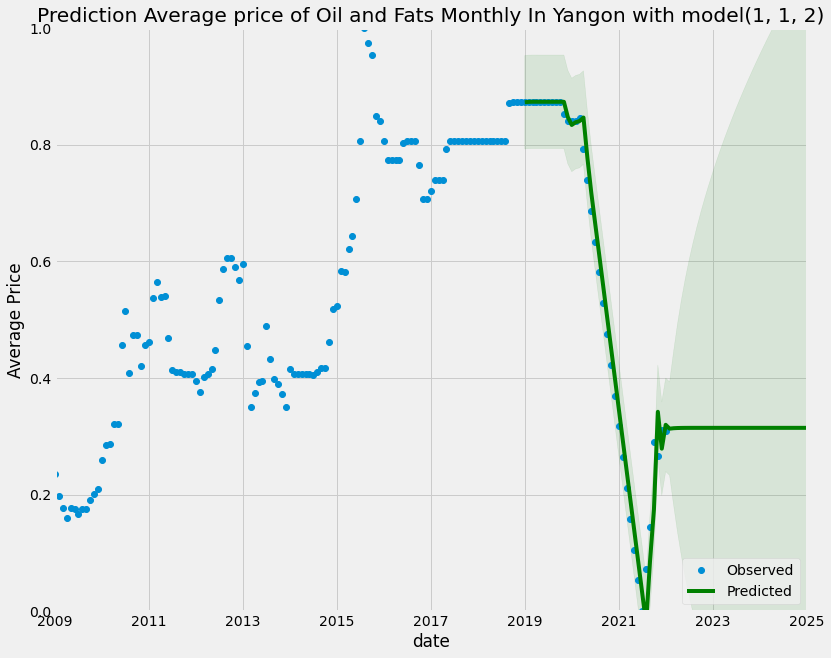

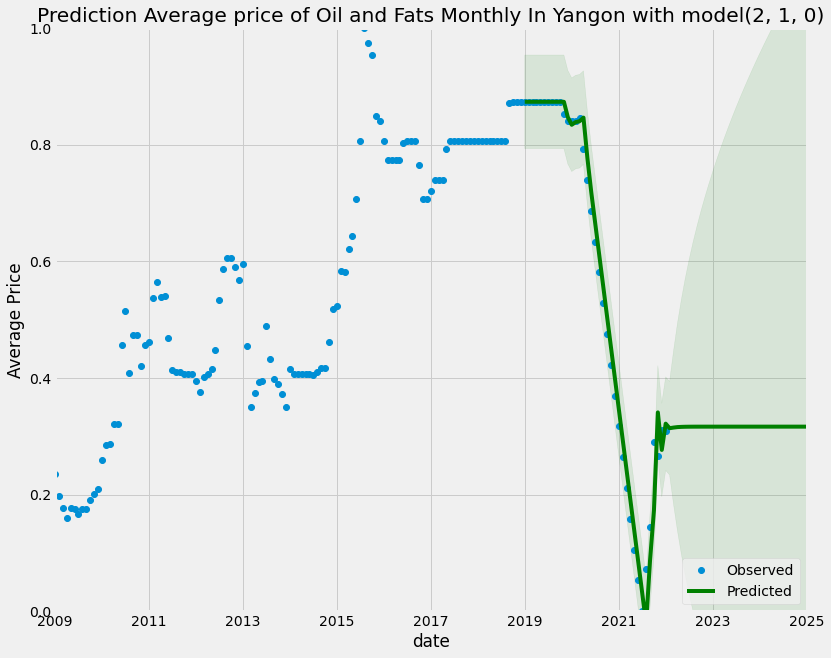

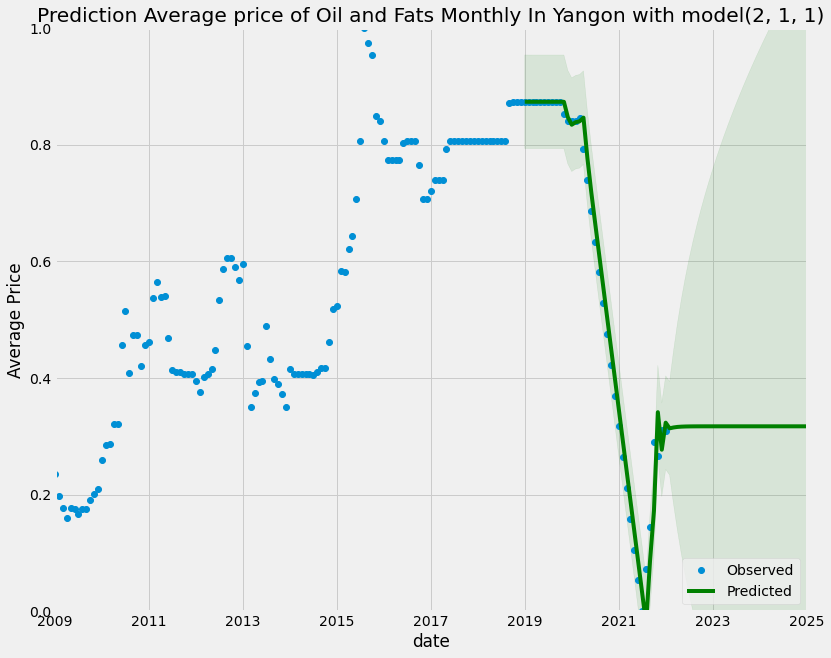

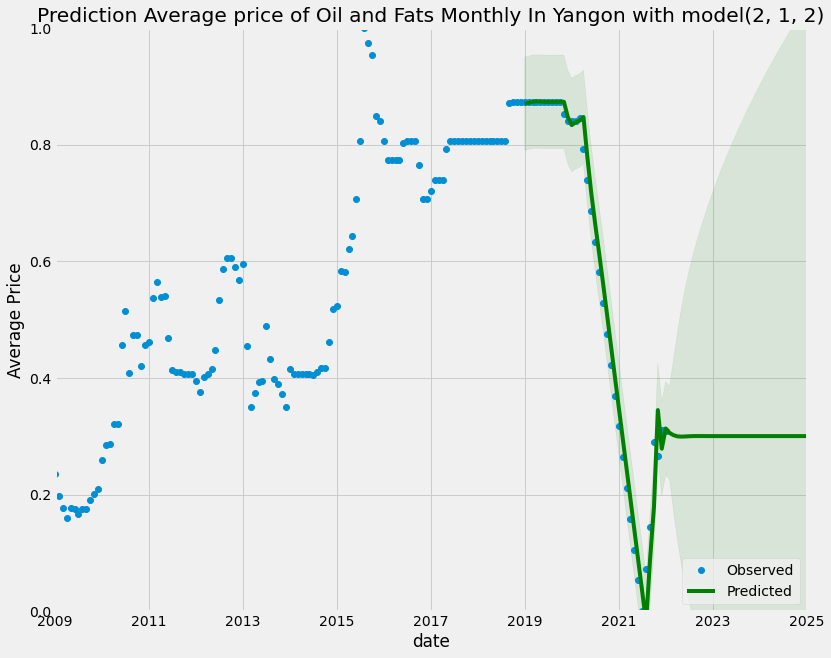

In [29]:
DOFM_Y_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DOFM_Y, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Oil and Fats Monthly In Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DOFM_Y_models.append(model)

Now we choose (0,1,0)

In [30]:
DOFM_Y_model = DOFM_Y_models[0]

In [31]:
DOFM_Y_pred_normalized = DOFM_Y_model.predict(pred_st_date, pred_end_date)
DOFM_Y_pred_normalized

2019-01-01    0.873661
2019-02-01    0.873661
2019-03-01    0.873661
2019-04-01    0.873661
2019-05-01    0.873661
                ...   
2024-09-01    0.309501
2024-10-01    0.309501
2024-11-01    0.309501
2024-12-01    0.309501
2025-01-01    0.309501
Freq: MS, Name: predicted_mean, Length: 73, dtype: float64

We need to un-normalized the predicted value to get actual price

In [32]:
pred_date = DOFM_Y_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2019-01-01', '2019-02-01', '2019-03-01', '2019-04-01',
               '2019-05-01', '2019-06-01', '2019-07-01', '2019-08-01',
               '2019-09-01', '2019-10-01', '2019-11-01', '2019-12-01',
               '2020-01-01', '2020-02-01', '2020-03-01', '2020-04-01',
               '2020-05-01', '2020-06-01', '2020-07-01', '2020-08-01',
               '2020-09-01', '2020-10-01', '2020-11-01', '2020-12-01',
               '2021-01-01', '2021-02-01', '2021-03-01', '2021-04-01',
               '2021-05-01', '2021-06-01', '2021-07-01', '2021-08-01',
               '2021-09-01', '2021-10-01', '2021-11-01', '2021-12-01',
               '2022-01-01', '2022-02-01', '2022-03-01', '2022-04-01',
               '2022-05-01', '2022-06-01', '2022-07-01', '2022-08-01',
               '2022-09-01', '2022-10-01', '2022-11-01', '2022-12-01',
               '2023-01-01', '2023-02-01', '2023-03-01', '2023-04-01',
               '2023-05-01', '2023-06-01', '2023-07-01', '2023-08-01',
      

In [33]:
DOFM_Y_pred_normalized_df = pd.DataFrame(DOFM_Y_pred_normalized)
DOFM_Y_pred_normalized_df = DOFM_Y_pred_normalized_df[:-1] # the last index doesn't need
DOFM_Y_pred_normalized_df

,predicted_mean
2019-01-01,0.873661
2019-02-01,0.873661
2019-03-01,0.873661
2019-04-01,0.873661
2019-05-01,0.873661
...,...
2024-08-01,0.309501
2024-09-01,0.309501
2024-10-01,0.309501
2024-11-01,0.309501


##### Un-normalization data

In [34]:
DOFM_Y_pred_act = scaler.inverse_transform(DOFM_Y_pred_normalized_df)
DOFM_Y_pred_act_df = pd.DataFrame(DOFM_Y_pred_act)
DOFM_Y_pred_act_df['date'] = pred_date
DOFM_Y_pred_act_df.columns = ['Predicted Price', 'date']
DOFM_Y_pred_act_df.set_index('date',  inplace=True)
DOFM_Y_pred_act_df

,Predicted Price
date,
2019-01-01,5000.0
2019-02-01,5000.0
2019-03-01,5000.0
2019-04-01,5000.0
2019-05-01,5000.0
...,...
2024-08-01,3308.8
2024-09-01,3308.8
2024-10-01,3308.8
